# $\log(5/3)$: historical CMF recovery

Exact rational approximants, sampled up to index 500.
$\delta_N=-1-\log|\alpha-p_N/q_N|/\log q_N$ and
$D_N=-\log_{10}|\alpha-p_N/q_N|$, with reduced $p_N/q_N$.
Published results and finite-depth measurements are distinct; source-index exceptions are stated below.

In [ ]:
%pip -q install ramanujantools==0.0.8 sympy==1.14.0 python-flint==0.9.0 matplotlib==3.11.2

## Setup

In [1]:
import sys
import matplotlib.pyplot as plt
import sympy as sp
from flint import arb, ctx
from IPython.display import Markdown, display
from ramanujantools.cmf.pfq import pFq

sys.set_int_max_str_digits(0)
DEPTHS = list(range(10, 501, 10))
results, accuracy = {}, {}
x0, x1, y0 = sp.symbols('x0 x1 y0')
a, b = (3, 2)
target = lambda: (arb(5)/3).log()


def measure(approximant, target):
    p, q = int(approximant.p), int(approximant.q)
    with ctx.workprec(4 * q.bit_length() + 256):
        error = abs(target() - arb(p) / q)
        assert error > 0 and q > 1
        value = -1 - error.log() / arb(q).log()
        assert value.is_finite() and value.rad() < arb("1e-18")
        return float(value.mid()), float((-error.log() / arb(10).log()).mid())

## 1. Alladi–Robinson (1980), logarithmic family

[Zeilberger–Zudilin (2019), author-hosted supplementary theorem and proof](https://www.math.ru.nl/~wzudilin/gat/oALLADI1.txt).

**CMF:** rank 2, full independent axes $(x_0,x_1,y_0)$ of ${}_2F_1(x_0,x_1;y_0;-b/a)$. Start $(1,1;2)$, direction $(1,1;2)$. After N steps its first function is the beta-normalized $E_N$; **walk depth N equals source index N**, with no offset.

In [5]:
cmf = pFq(2, 1, -sp.Rational(b, a))
start = {x0: 1, x1: 1, y0: 2}
trajectory = {x0: 1, x1: 1, y0: 2}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [-b * W[1, 0] / ((a + b) * (W[0, 0] - W[1, 0])) for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Alladi-Robinson (1980)'] = (DEPTHS, deltas)
accuracy['Alladi-Robinson (1980)'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.115614781938


## Comparison

Only completed runs are shown. N follows each example’s stated index convention.

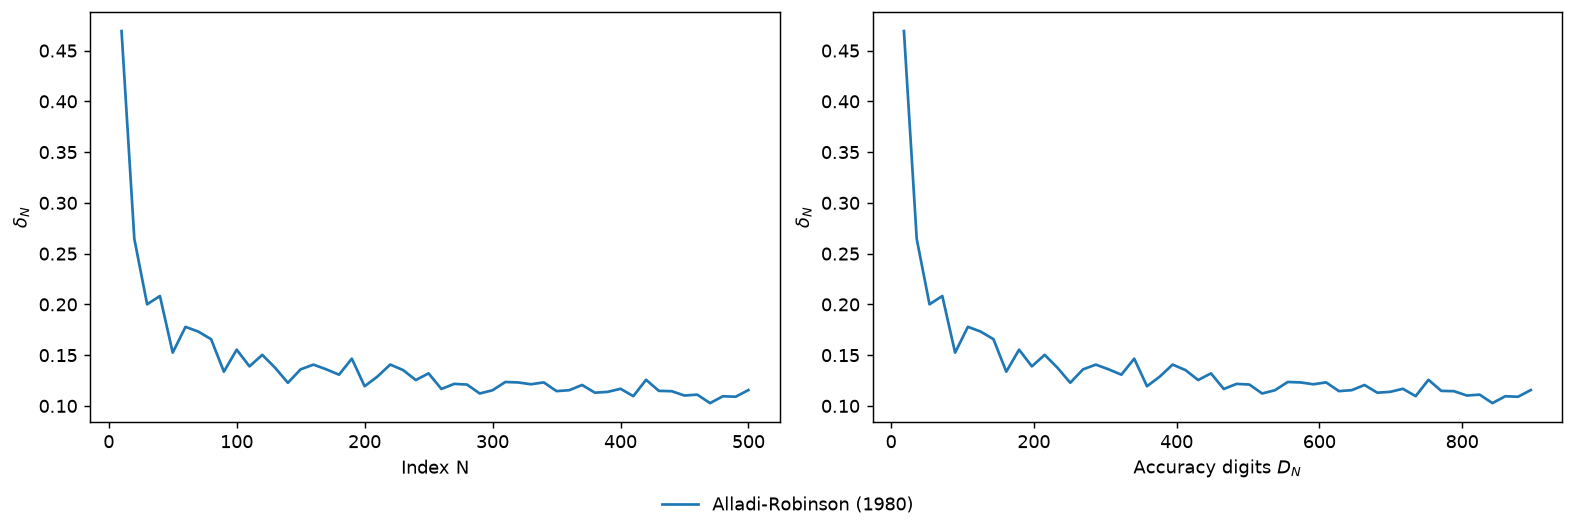

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for name, (depths, deltas) in results.items():
    axes[0].plot(depths, deltas, label=name)
    axes[1].plot(accuracy[name], deltas)
axes[0].set(xlabel="Index N", ylabel=r"$\delta_N$")
axes[1].set(xlabel=r"Accuracy digits $D_N$", ylabel=r"$\delta_N$")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=2, frameon=False)
plt.show()

## Historical overview

Only implemented CMF recoveries are listed. The measured column states the actual final index.

In [9]:
bounds = {
    'Alladi-Robinson (1980)': '11.144981993272',
}
rows = ["| Construction | Published result | Measured delta |", "|:--|:--|:--|"]
for name, bound in bounds.items():
    if name in results:
        depths, deltas = results[name]
        value = f"{deltas[-1]:.12f} (N = {depths[-1]})"
    else:
        value = "Not computed"
    rows.append(f"| {name} | {bound} | {value} |")
display(Markdown("\n".join(rows)))

| Construction | Published result | Measured delta |
|:--|:--|:--|
| Alladi-Robinson (1980) | 11.144981993272 | 0.115614781938 (N = 500) |